# PathSnap: Phase 1 results
Every table and figure here is loaded from `results/`, as written by the scripts in `scripts/` (see README for the run order).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
R = Path('..') / 'results'
pd.set_option('display.precision', 4)
pd.set_option('display.width', 200)

## 1. EDA

In [2]:
summary = json.loads((R / 'eda' / 'eda_summary.json').read_text())
pd.DataFrame(summary)

,student_test,train
n_trips,10.0000,8.0000e+01
total_points,19160.0000,2.0842e+05
points_per_trip_median,1420.0000,1.5290e+03
duration_min_median,30.1583,2.8500e+01
dt_median_s,1.0000,1.0000e+00
trips_with_gaps_over_60s,1.0000,2.2000e+01
speed_median_mps,14.1456,1.1078e+01
arcs_per_network_median,13145.0000,1.9526e+04
route_km_median,14.7688,1.4319e+01
two_way_arc_frac_mean,0.9269,9.2167e-01


In [3]:
pd.read_csv(R / 'eda' / 'per_trip_stats.csv').describe().T

,count,mean,std,min,25%,50%,75%,max
trip,90.0,49.2889,29.1560,0.0000,25.2500,49.0000,74.7500,99.0000
n_points,90.0,2528.6333,3156.9999,262.0000,899.2500,1496.5000,2816.2500,19313.0000
duration_min,90.0,87.9041,287.3336,4.4167,18.8967,28.5000,60.3125,2567.1667
dt_median_s,90.0,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
dt_p95_s,90.0,1.7494,2.2715,1.0000,1.0000,1.0000,1.0000,17.0000
n_gaps_over_60s,90.0,0.7778,2.4939,0.0000,0.0000,0.0000,0.7500,17.0000
speed_median_mps,90.0,14.8814,7.3647,5.6427,9.9800,12.8061,17.7511,41.3813
speed_p95_mps,90.0,27.6023,9.2532,14.4565,21.6274,25.8680,31.4266,65.9692
gps_path_km,90.0,36.4384,33.4189,5.5592,12.7840,24.0385,48.8136,169.5866
n_nodes,90.0,22490.8222,30868.5263,299.0000,3655.2500,9305.0000,26296.5000,155003.0000


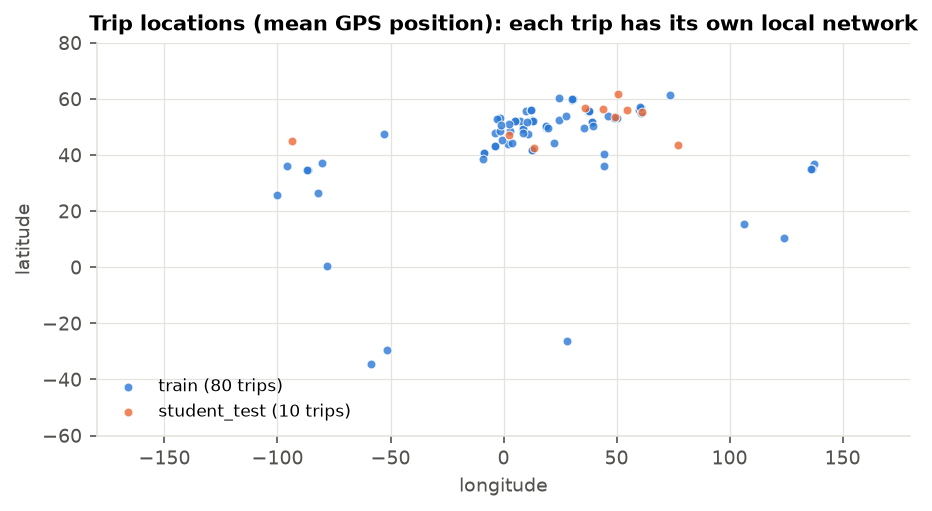

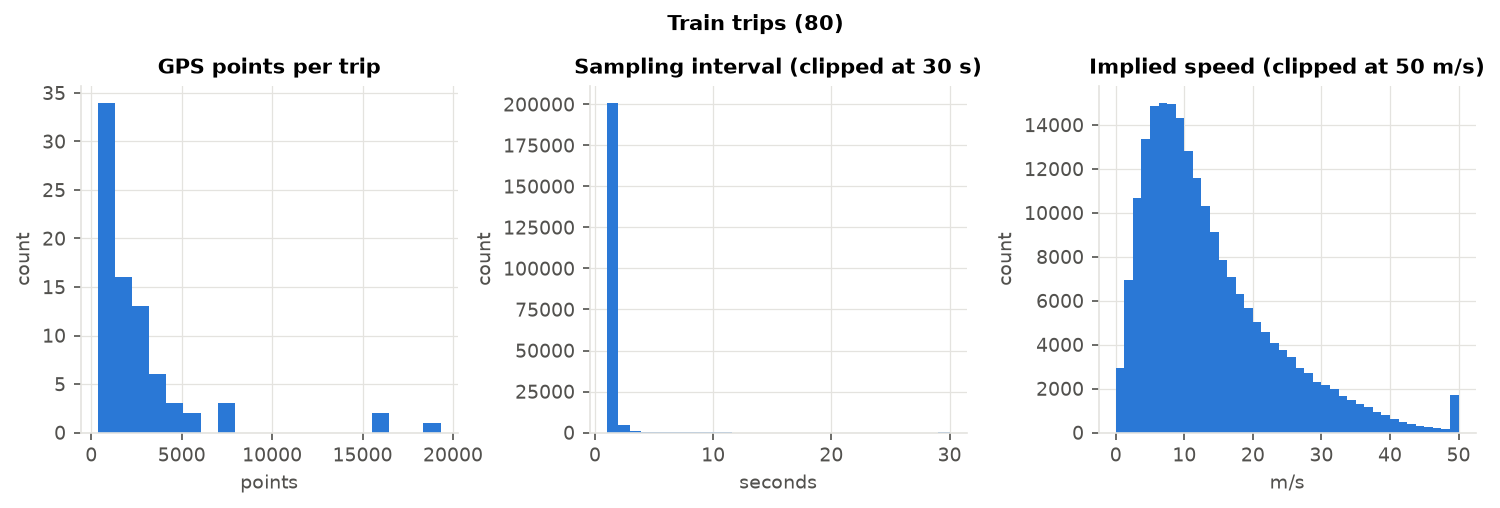

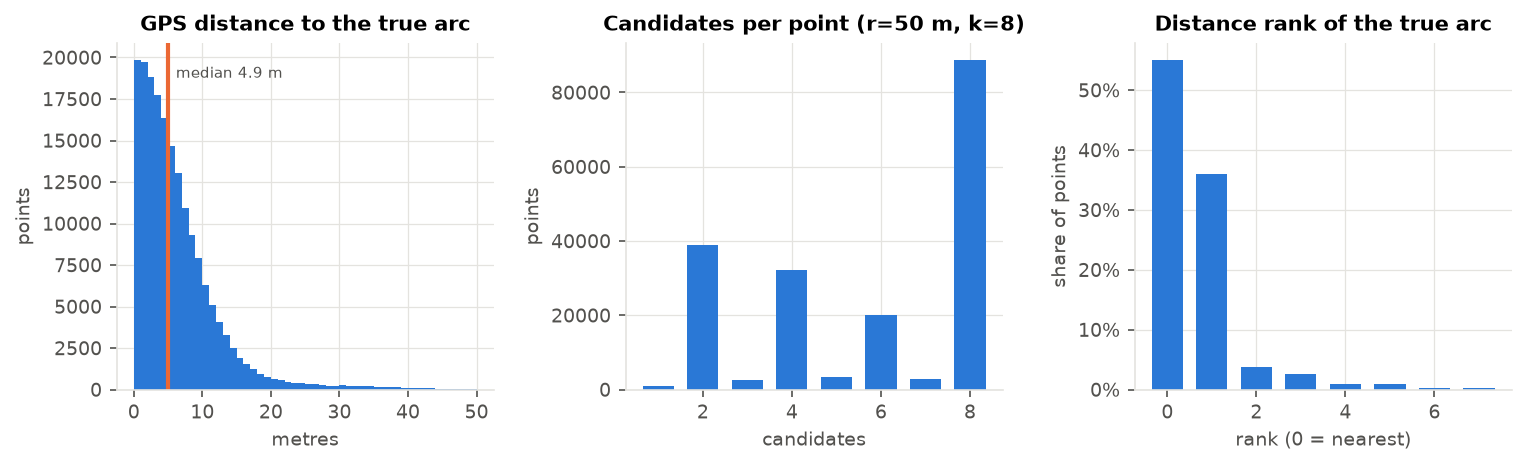

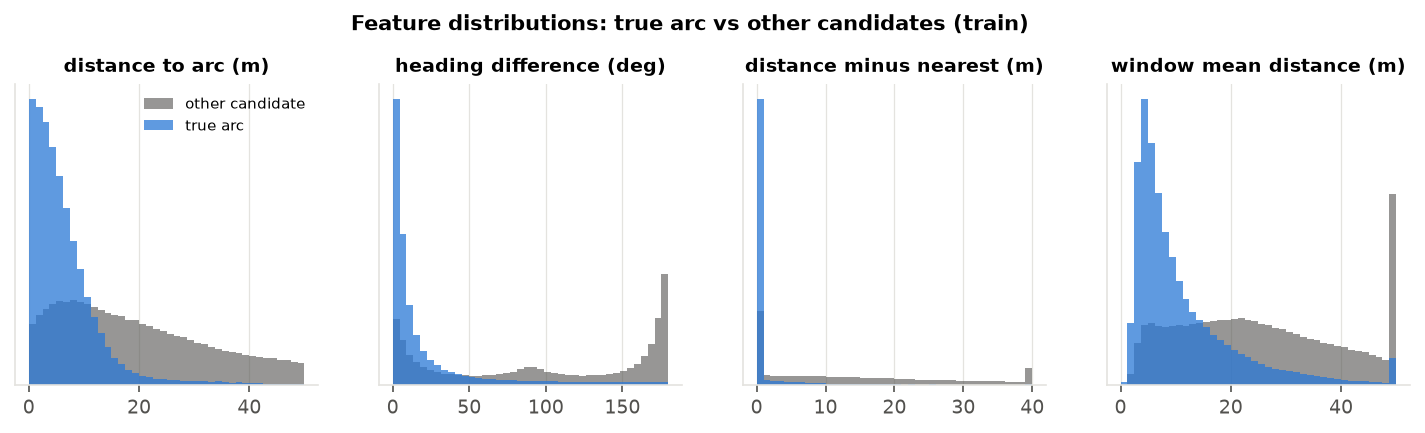

In [4]:
for p in ['eda_trip_locations', 'eda_trips', 'eda_candidates', 'eda_features']:
    display(Image(R / 'plots' / f'{p}.png'))

Folium EDA maps: `results/maps/eda_train_*.html` (open in a browser).

## 2. HMM/Viterbi baseline (Gaussian distance emission)

In [5]:
pd.read_csv(R / 'hmm_baseline_summary.csv')

,partition,n_points,labelled_frac,label_dist_p50,cands_per_point,candidate_miss_rate,top1_nearest,top1_hmm,continuity_nearest,continuity_hmm,n_breaks,decode_s,total_s,route_precision,route_recall,route_f1
0,student_test,1916.0000,1.0000,5.1296,6.1082,0.0159,0.5503,0.9314,0.8935,0.9991,1.1000,0.2019,0.5503,0.9767,0.9961,0.9862
1,train,2605.2125,0.9935,8.0455,6.1410,0.0352,0.5571,0.9028,0.8761,0.9983,3.5875,0.2203,0.7108,0.9676,0.9886,0.9775


## 3. Classifiers: GroupKFold CV on train, then student_test
`*_clf` = classifier only (argmax per point); `*_hmm` = classifier probabilities as HMM emissions.

In [6]:
mc = pd.read_csv(R / 'model_comparison.csv')
cols = ['model', 'family', 'cv_macro_f1', 'cv_macro_f1_std', 'cv_log_loss', 'top1_clf', 'top1_hmm',
        'route_f1_clf', 'route_f1_hmm', 'continuity_clf', 'continuity_hmm', 'test_macro_f1',
        'test_log_loss', 'train_fit_s', 'infer_ms_per_point_model']
mc[[c for c in cols if c in mc]]

,model,family,cv_macro_f1,cv_macro_f1_std,cv_log_loss,top1_clf,top1_hmm,route_f1_clf,route_f1_hmm,continuity_clf,continuity_hmm,test_macro_f1,test_log_loss,train_fit_s,infer_ms_per_point_model
0,hmm_baseline,HMM only (Gaussian distance emission),NaN,NaN,NaN,0.5249,0.9236,0.8709,0.9862,0.8935,0.9991,NaN,NaN,NaN,3.9029e-05
1,logreg,Linear,0.8998,0.0170,0.1602,0.8527,0.8996,0.9413,0.9878,0.9646,0.9990,0.9033,0.1489,1.2819,8.2796e-04
2,gnb,Probabilistic,0.8356,0.0211,0.6197,0.8354,0.8925,0.9302,0.9832,0.9574,0.9986,0.8333,0.6245,0.1427,8.8091e-04
3,knn,Instance-based,0.9055,0.0206,0.2020,0.8562,0.8966,0.9416,0.9861,0.9639,0.9991,0.9125,0.1802,0.0745,5.8996e-01
4,rf,Ensemble (bagging),0.9212,0.0149,0.1146,0.8691,0.9115,0.9535,0.9889,0.9699,0.9991,0.9242,0.1046,88.4263,2.3236e-02
5,lightgbm,Boosting,0.9223,0.0158,0.1147,0.8721,0.9023,0.9599,0.9891,0.9750,0.9991,0.9253,0.1041,10.9841,2.2164e-02
6,xgboost,Boosting,0.9219,0.0157,0.1152,0.8726,0.9020,0.9577,0.9890,0.9731,0.9991,0.9255,0.1037,6.5456,4.4415e-03
7,mlp,Neural network,0.9136,0.0190,0.1258,0.8652,0.9054,0.9546,0.9889,0.9726,0.9991,0.9202,0.1157,13.8243,1.3686e-03


In [7]:
pd.read_csv(R / 'cv_folds.csv').pivot_table(index='model', columns='fold', values='macro_f1')

fold,0,1,2,3,4
model,,,,,
gnb,0.8377,0.8467,0.8433,0.8515,0.7990
knn,0.9012,0.9209,0.9030,0.9276,0.8746
lightgbm,0.9123,0.9395,0.9159,0.9388,0.9051
logreg,0.8944,0.9112,0.8959,0.9207,0.8766
mlp,0.9060,0.9302,0.9086,0.9348,0.8883
rf,0.9133,0.9373,0.9165,0.9358,0.9029
xgboost,0.9122,0.9390,0.9161,0.9379,0.9042


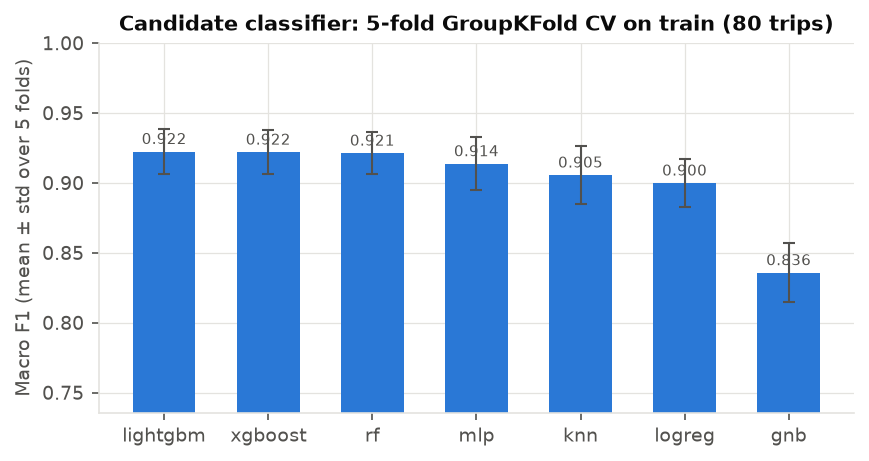

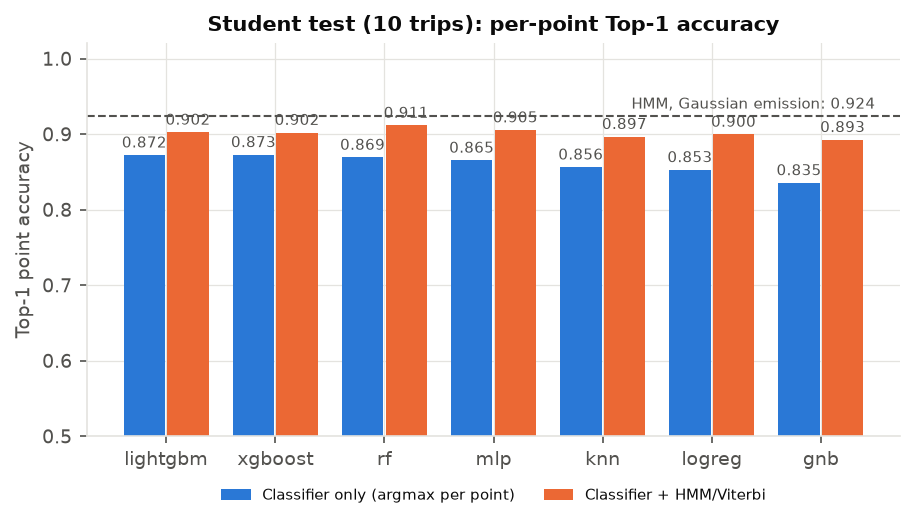

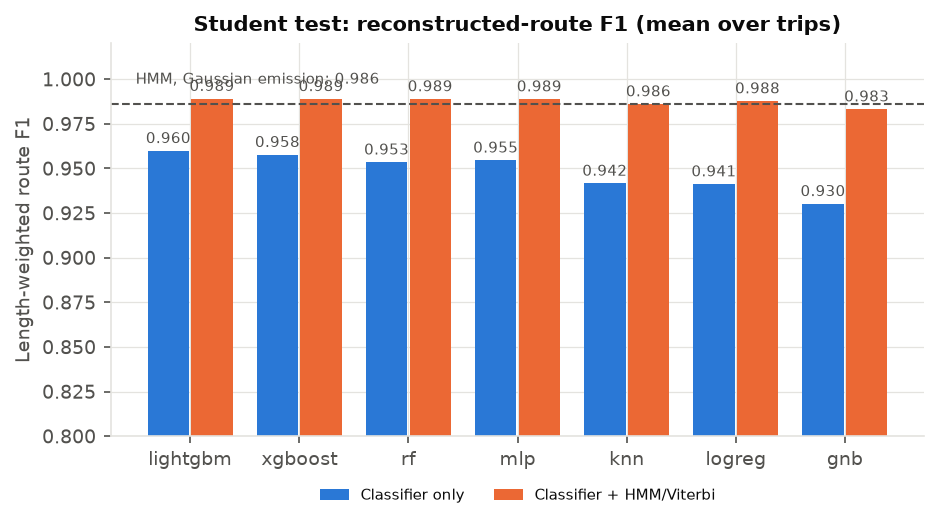

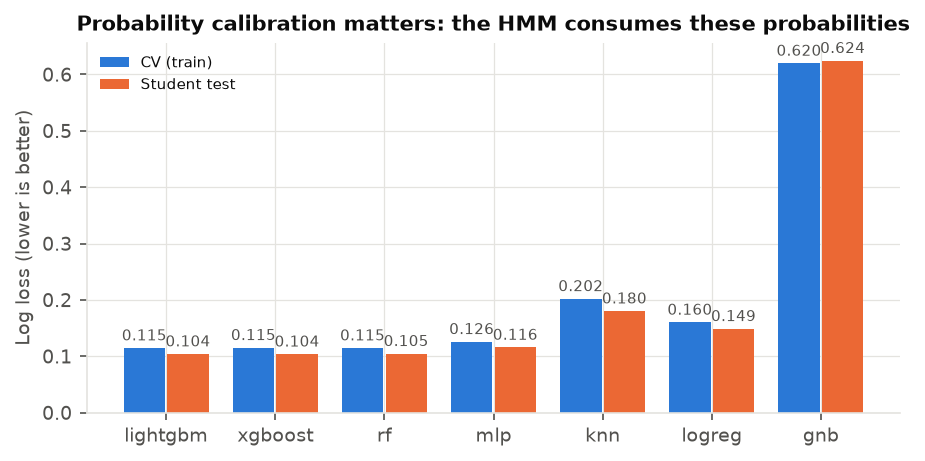

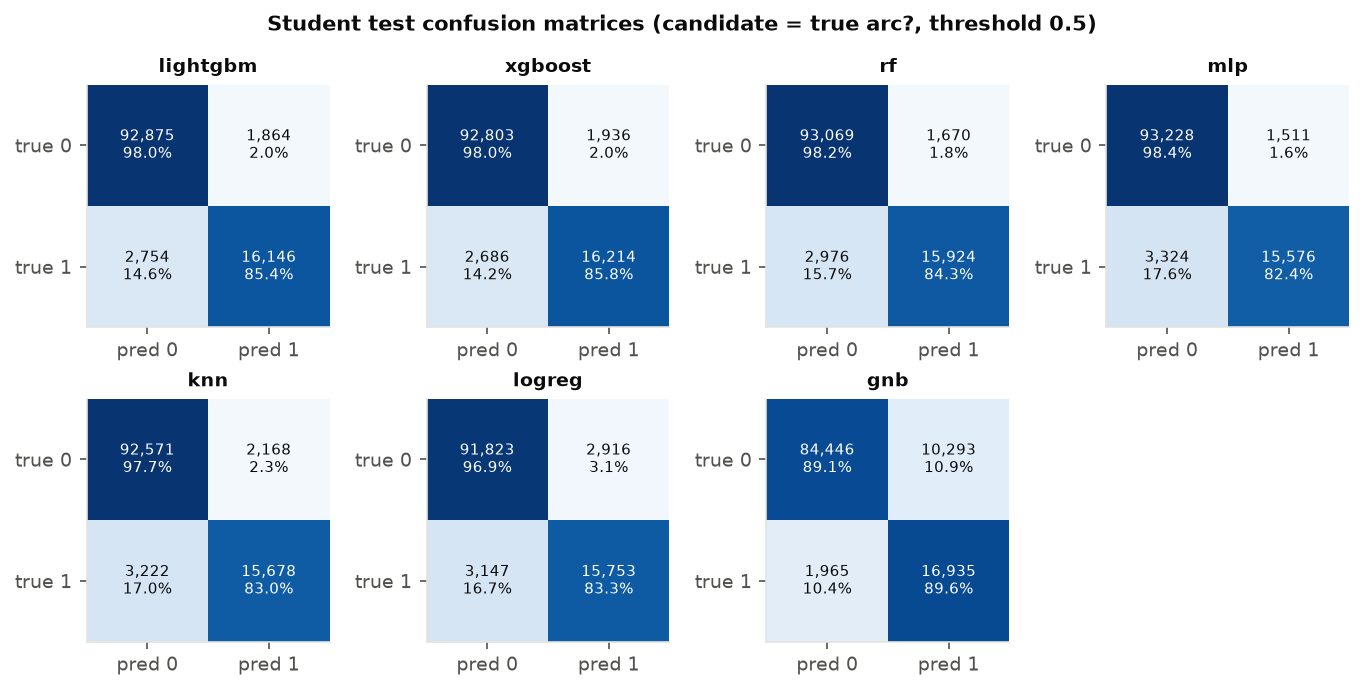

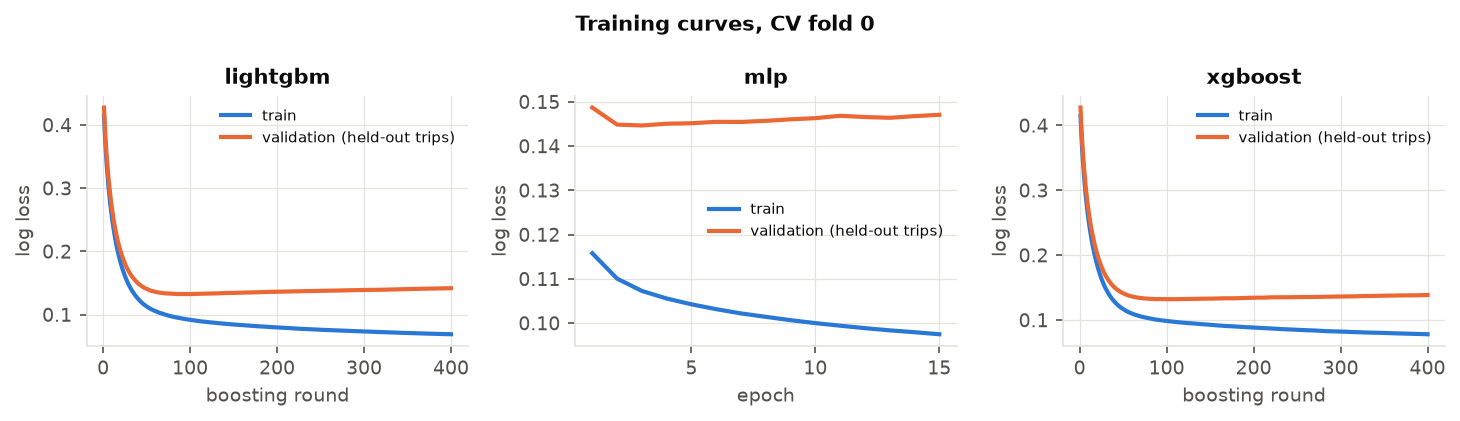

In [8]:
for p in ['cv_macro_f1', 'student_test_top1', 'student_test_route_f1', 'log_loss',
          'confusion_matrices', 'loss_curves']:
    display(Image(R / 'plots' / f'{p}.png'))

## 4. Bayesian optimisation (Optuna TPE, train only)

In [9]:
T = R / 'tuning'
for name in ['clf_lightgbm', 'hmm_baseline', 'hmm_hybrid']:
    f = T / f'{name}_best.json'
    if f.exists():
        print(name, json.dumps(json.loads(f.read_text()), indent=2))

clf_lightgbm {
  "study": "clf_lightgbm",
  "direction": "MINIMIZE",
  "best_value": 0.11325167075771914,
  "best_params": {
    "n_estimators": 600,
    "learning_rate": 0.010045133179650632,
    "num_leaves": 145,
    "min_child_samples": 50,
    "subsample": 0.6934483108826374,
    "colsample_bytree": 0.8544169022580052,
    "reg_lambda": 1.024372187930848
  },
  "best_trial": 27,
  "best_user_attrs": {
    "cv_macro_f1": 0.9226418272817949,
    "cv_macro_f1_std": 0.016109737917883823,
    "cv_top1_cand": 0.8531663462682924
  },
  "n_trials": 30,
  "n_complete": 20,
  "n_pruned": 10,
  "total_compute_s": 2552.718596,
  "mean_trial_s": 102.93542984999999,
  "objective": "mean 5-fold GroupKFold candidate log loss (train trips only)",
  "param_importance": {
    "num_leaves": 0.333977670275687,
    "reg_lambda": 0.1853696992386465,
    "colsample_bytree": 0.1799294897930761,
    "learning_rate": 0.1605351300965268,
    "min_child_samples": 0.10450637850291081,
    "subsample": 0.027758

clf_lightgbm: 30 trials, states: {'COMPLETE': 20, 'PRUNED': 10}


,number,value,datetime_start,datetime_complete,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_lambda,params_subsample,user_attrs_cv_macro_f1,user_attrs_cv_macro_f1_std,user_attrs_cv_top1_cand,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state,duration_s
0,0,0.1147,2026-11-18 11:20:46.723000,2026-11-18 11:21:40.651483,0.8000,0.0500,50,400,63,1.0000,0.8000,0.9223,0.0158,0.8528,"{'n_estimators': 400, 'learning_rate': 0.05, '...",NaN,COMPLETE,53.9285
1,1,0.1812,2026-11-18 11:21:40.654519,2026-11-18 11:23:07.288181,0.4936,0.1725,75,400,118,0.0018,0.5780,0.9146,0.0187,0.8391,NaN,NaN,COMPLETE,86.6337
2,2,0.1215,2026-11-18 11:23:07.291196,2026-11-18 11:25:23.080177,0.8995,0.0605,10,800,111,0.0082,0.9850,0.9210,0.0168,0.8523,NaN,NaN,COMPLETE,135.7890
3,3,0.1168,2026-11-18 11:25:23.083083,2026-11-18 11:25:49.608064,0.5747,0.0173,58,250,35,0.4282,0.7160,0.9224,0.0143,0.8513,NaN,NaN,COMPLETE,26.5250
4,4,0.1144,2026-11-18 11:25:49.610910,2026-11-18 11:26:17.076699,0.5198,0.0240,46,250,41,0.1628,0.8926,0.9224,0.0145,0.8522,NaN,NaN,COMPLETE,27.4658
5,5,0.1139,2026-11-18 11:26:17.079274,2026-11-18 11:27:55.255773,0.9693,0.0115,17,600,83,14.2302,0.5325,0.9222,0.0157,0.8526,NaN,NaN,COMPLETE,98.1765
6,6,0.1141,2026-11-18 11:27:55.258609,2026-11-18 11:28:46.548044,0.4732,0.0249,101,750,19,0.1348,0.7201,0.9228,0.0146,0.8528,NaN,NaN,COMPLETE,51.2894
7,7,0.1126,2026-11-18 11:28:46.550379,2026-11-18 11:28:51.535405,0.7120,0.1524,94,150,30,0.2246,0.6559,NaN,NaN,NaN,NaN,NaN,PRUNED,4.9850
8,8,0.1213,2026-11-18 11:28:51.537911,2026-11-18 11:29:14.525752,0.7587,0.1826,244,250,134,9.2259,0.9474,NaN,NaN,NaN,NaN,NaN,PRUNED,22.9878
9,9,0.1170,2026-11-18 11:29:14.528630,2026-11-18 11:29:20.581416,0.5628,0.0180,29,200,17,3.6680,0.6943,NaN,NaN,NaN,NaN,NaN,PRUNED,6.0528


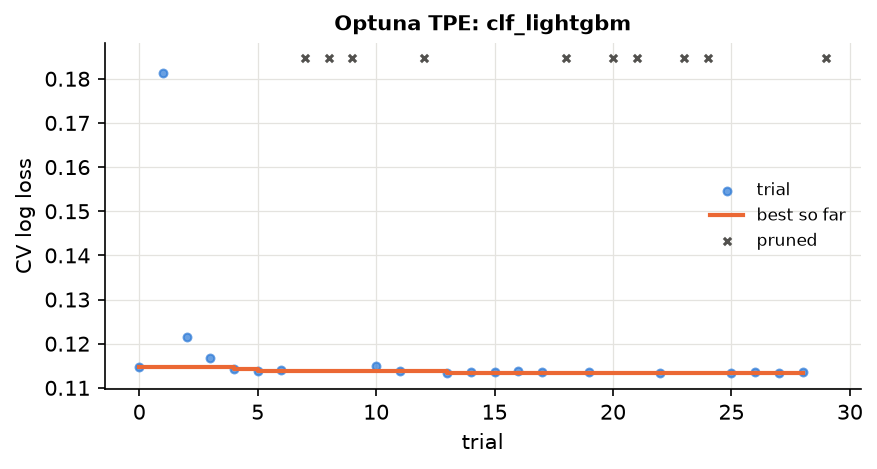

hmm_baseline: 50 trials, states: {'COMPLETE': 50}


,number,value,datetime_start,datetime_complete,params_beta,params_sigma,user_attrs_n_breaks,user_attrs_train_route_f1,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state,duration_s
0,0,0.8521,2026-11-18 12:06:51.824856,2026-11-18 12:06:55.244712,5.0000,5.0000,287,0.9775,"{'sigma': 5.0, 'beta': 5.0}",NaN,COMPLETE,3.4199
1,1,0.8415,2026-11-18 12:06:55.250344,2026-11-18 12:06:58.476725,41.2321,5.5147,287,0.9681,NaN,NaN,COMPLETE,3.2264
2,2,0.8557,2026-11-18 12:06:58.480114,2026-11-18 12:07:01.795270,10.4017,14.5185,287,0.9789,NaN,NaN,COMPLETE,3.3152
3,3,0.8521,2026-11-18 12:07:01.800085,2026-11-18 12:07:05.126668,1.8409,3.0516,287,0.9775,NaN,NaN,COMPLETE,3.3266
4,4,0.8316,2026-11-18 12:07:05.129912,2026-11-18 12:07:08.439210,29.6215,2.3407,287,0.9546,NaN,NaN,COMPLETE,3.3093
5,5,0.8532,2026-11-18 12:07:08.441924,2026-11-18 12:07:11.655882,15.9586,10.1858,287,0.9784,NaN,NaN,COMPLETE,3.2140
6,6,0.8280,2026-11-18 12:07:11.659190,2026-11-18 12:07:15.156408,44.4475,2.1147,287,0.9484,NaN,NaN,COMPLETE,3.4972
7,7,0.8426,2026-11-18 12:07:15.159736,2026-11-18 12:07:18.371202,2.2949,19.0572,287,0.9790,NaN,NaN,COMPLETE,3.2115
8,8,0.8522,2026-11-18 12:07:18.374106,2026-11-18 12:07:21.590941,2.0493,3.2724,287,0.9777,NaN,NaN,COMPLETE,3.2168
9,9,0.8489,2026-11-18 12:07:21.593654,2026-11-18 12:07:25.114598,7.7901,4.5588,287,0.9755,NaN,NaN,COMPLETE,3.5209


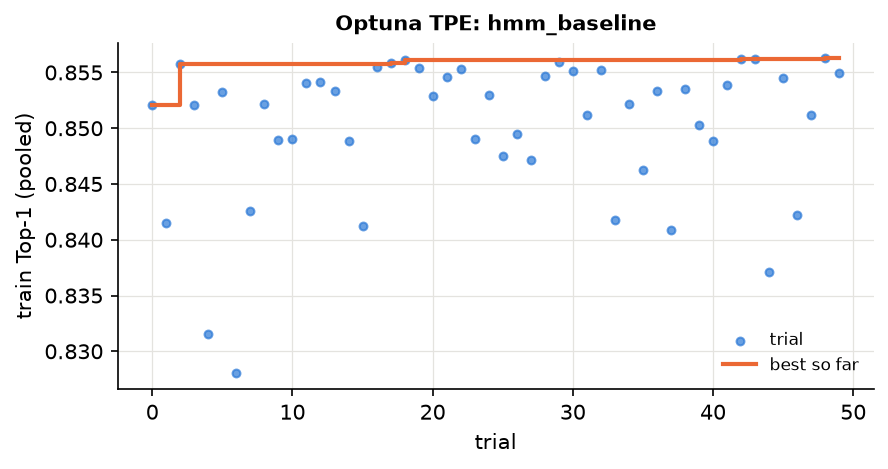

hmm_hybrid: 50 trials, states: {'COMPLETE': 50}


,number,value,datetime_start,datetime_complete,params_beta,params_clf_weight,params_dist_sigma,params_use_dist,user_attrs_n_breaks,user_attrs_train_route_f1,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state,duration_s
0,0,0.8447,2026-11-18 12:09:25.792802,2026-11-18 12:09:28.762980,5.0000,1.0000,NaN,False,287,0.9793,"{'clf_weight': 1.0, 'use_dist': False, 'beta':...",NaN,COMPLETE,2.9702
1,1,0.8510,2026-11-18 12:09:28.766589,2026-11-18 12:09:32.318102,1.8411,0.2806,15.3222,True,287,0.9802,NaN,NaN,COMPLETE,3.5515
2,2,0.8502,2026-11-18 12:09:32.321135,2026-11-18 12:09:35.875879,10.5021,0.1026,NaN,False,287,0.9802,NaN,NaN,COMPLETE,3.5547
3,3,0.8371,2026-11-18 12:09:35.880550,2026-11-18 12:09:39.362482,25.9594,1.3035,NaN,False,287,0.9759,NaN,NaN,COMPLETE,3.4819
4,4,0.8460,2026-11-18 12:09:39.365277,2026-11-18 12:09:42.304574,3.2877,0.1329,NaN,False,287,0.9790,NaN,NaN,COMPLETE,2.9393
5,5,0.8504,2026-11-18 12:09:42.307495,2026-11-18 12:09:45.333693,1.7258,0.5604,16.0255,True,287,0.9798,NaN,NaN,COMPLETE,3.0262
6,6,0.8460,2026-11-18 12:09:45.337894,2026-11-18 12:09:48.335680,21.5770,0.1920,NaN,False,287,0.9793,NaN,NaN,COMPLETE,2.9978
7,7,0.8388,2026-11-18 12:09:48.340113,2026-11-18 12:09:51.284380,1.1993,0.1254,NaN,False,287,0.9782,NaN,NaN,COMPLETE,2.9443
8,8,0.8369,2026-11-18 12:09:51.288018,2026-11-18 12:09:54.228800,43.7099,0.8205,50.4254,True,287,0.9756,NaN,NaN,COMPLETE,2.9408
9,9,0.8414,2026-11-18 12:09:54.232148,2026-11-18 12:09:57.156387,5.5951,2.0690,20.4986,True,287,0.9783,NaN,NaN,COMPLETE,2.9242


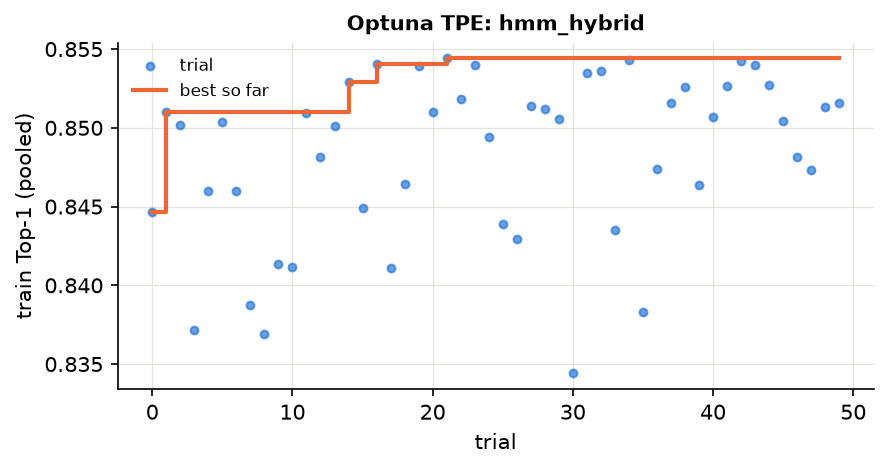

In [10]:
for name in ['clf_lightgbm', 'hmm_baseline', 'hmm_hybrid']:
    f = T / f'{name}_trials.csv'
    if f.exists():
        t = pd.read_csv(f)
        print(f'{name}: {len(t)} trials, states: {t.state.value_counts().to_dict()}')
        display(t.head(10))
    p = R / 'plots' / f'tuning_{name}.png'
    if p.exists():
        display(Image(p))

## 5. Final selection (by train objective) and student_test report

In [11]:
print(json.dumps(json.loads((T / 'selection.json').read_text()), indent=2, default=str))

{
  "chosen": "hmm_baseline_tuned",
  "rule": "highest pooled train Top-1 after Viterbi (OOF emissions)",
  "train_top1_hmm_baseline_tuned": 0.856251909811799,
  "train_top1_hybrid_tuned": 0.8544034624574832,
  "hmm_baseline": {
    "hmm": {
      "beta": 30.602919949158224,
      "sigma": 21.757283655611495,
      "gap_s": 60.0,
      "back_tol": 15.0,
      "max_speed": 60.0,
      "sp_slack": 200.0,
      "sp_cap": 3000.0
    }
  },
  "hybrid": {
    "model": "lightgbm_tuned",
    "lgbm_params": {
      "n_estimators": 600,
      "learning_rate": 0.010045133179650632,
      "num_leaves": 145,
      "min_child_samples": 50,
      "subsample": 0.6934483108826374,
      "colsample_bytree": 0.8544169022580052,
      "reg_lambda": 1.024372187930848
    },
    "hmm": {
      "beta": 2.5067485340577864,
      "sigma": 5.0,
      "gap_s": 60.0,
      "back_tol": 15.0,
      "max_speed": 60.0,
      "sp_slack": 200.0,
      "sp_cap": 3000.0
    },
    "emission_weight": 0.0986011483896138,
 

In [12]:
pd.read_csv(T / 'final_comparison.csv')

,system,beta,sigma,clf_weight,dist_sigma,top1_clf,top1_hmm,continuity_clf,continuity_hmm,route_f1_clf,route_f1_hmm,infer_ms_per_point_model,infer_ms_per_point_hmm,test_macro_f1,test_macro_precision,test_macro_recall,test_log_loss,test_top1_cand
0,hmm_baseline (default),5.0000,5.0000,NaN,NaN,0.5249,0.9236,0.8935,0.9991,0.8709,0.9862,3.9755e-05,0.1096,NaN,NaN,NaN,NaN,NaN
1,hmm_baseline (tuned),30.6029,21.7573,NaN,NaN,0.5249,0.9294,0.8935,0.9992,0.8709,0.9883,4.1469e-05,0.1100,NaN,NaN,NaN,NaN,NaN
2,lightgbm default + HMM default,5.0000,NaN,1.0000,NaN,0.8721,0.9023,0.9750,0.9991,0.9599,0.9891,2.4475e-02,0.1163,0.9253,0.9339,0.9173,0.1041,0.8721
3,lightgbm tuned + HMM default,5.0000,NaN,1.0000,NaN,0.8738,0.9159,0.9725,0.9991,0.9555,0.9886,4.7659e-02,0.1107,0.9271,0.9347,0.9199,0.1029,0.8738
4,lightgbm tuned + HMM tuned (hybrid),2.5067,NaN,0.0986,6.5099,0.8738,0.9267,0.9725,0.9991,0.9555,0.9884,4.5387e-02,0.1103,0.9271,0.9347,0.9199,0.1029,0.8738


In [13]:
pd.read_csv(T / 'final_per_trip.csv')

,system,trip,top1_clf,top1_hmm,continuity_clf,continuity_hmm,route_f1_clf,route_f1_hmm,n_breaks
0,hmm_baseline (default),0,0.5226,0.9644,0.9293,0.9992,0.9366,0.9950,2
1,hmm_baseline (default),7,0.4719,0.8840,0.9490,1.0000,0.9864,0.9945,1
2,hmm_baseline (default),9,0.5167,0.8837,0.9227,0.9971,0.8679,0.9707,0
3,hmm_baseline (default),40,0.5342,0.9743,0.9329,1.0000,0.9348,1.0000,1
4,hmm_baseline (default),52,0.7786,1.0000,0.8084,1.0000,0.8156,0.9984,0
5,hmm_baseline (default),56,0.6718,0.9376,0.8519,0.9982,0.8723,0.9795,3
6,hmm_baseline (default),65,0.6719,0.9661,0.8709,0.9974,0.7858,0.9793,3
7,hmm_baseline (default),76,0.3984,0.9139,0.8855,0.9993,0.8509,0.9634,0
8,hmm_baseline (default),77,0.3884,0.8573,0.9368,0.9995,0.8635,0.9901,1
9,hmm_baseline (default),91,0.5481,0.9325,0.8477,1.0000,0.7950,0.9910,0


## 6. Exported bundle

In [14]:
print((Path('..') / 'artifacts' / 'pathsnap_config.json').read_text())

{
  "model_name": "hmm_baseline_tuned",
  "hmm": {
    "beta": 30.602919949158224,
    "sigma": 21.757283655611495,
    "gap_s": 60.0,
    "back_tol": 15.0,
    "max_speed": 60.0,
    "sp_slack": 200.0,
    "sp_cap": 3000.0
  },
  "emission_weight": 1.0,
  "dist_sigma": null,
  "features": [
    "dist",
    "rank",
    "n_cands",
    "dist_minus_min",
    "dist_ratio_min",
    "t_offset",
    "arc_length",
    "heading_diff",
    "heading_cos",
    "gps_disp",
    "gps_speed",
    "win_dist_mean",
    "win_dist_max",
    "win_heading_diff",
    "has_reverse",
    "out_deg_v",
    "in_deg_u",
    "dt_prev"
  ],
  "radius": 50.0,
  "k": 8,
  "created": "2026-11-18T06:43:56+00:00",
  "trained_on": "train (80 trips); hyperparameters tuned with Optuna TPE on train only",
  "selection_rule": "highest pooled train Top-1 after Viterbi (OOF emissions)"
}


Prediction maps: `results/maps/index.html`.